In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                        f1_score, classification_report, confusion_matrix)

In [2]:
df = pd.read_csv("dataset/tmdb_5000_movies.csv")
print(df.shape)
df.head()

(4803, 20)


,budget,genres,homepage,id,keywords,original_language,original_title,overview,popularity,production_companies,production_countries,release_date,revenue,runtime,spoken_languages,status,tagline,title,vote_average,vote_count
0,237000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.avatarmovie.com/,19995,"[{""id"": 1463, ""name"": ""culture clash""}, {""id"":...",en,Avatar,"In the 22nd century, a paraplegic Marine is di...",150.437577,"[{""name"": ""Ingenious Film Partners"", ""id"": 289...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2009-12-10,2787965087,162.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}, {""iso...",Released,Enter the World of Pandora.,Avatar,7.2,11800
1,300000000,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""...",http://disney.go.com/disneypictures/pirates/,285,"[{""id"": 270, ""name"": ""ocean""}, {""id"": 726, ""na...",en,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...",139.082615,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}, {""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2007-05-19,961000000,169.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"At the end of the world, the adventure begins.",Pirates of the Caribbean: At World's End,6.9,4500
2,245000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.sonypictures.com/movies/spectre/,206647,"[{""id"": 470, ""name"": ""spy""}, {""id"": 818, ""name...",en,Spectre,A cryptic message from Bond’s past sends him o...,107.376788,"[{""name"": ""Columbia Pictures"", ""id"": 5}, {""nam...","[{""iso_3166_1"": ""GB"", ""name"": ""United Kingdom""...",2015-10-26,880674609,148.0,"[{""iso_639_1"": ""fr"", ""name"": ""Fran\u00e7ais""},...",Released,A Plan No One Escapes,Spectre,6.3,4466
3,250000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 80, ""nam...",http://www.thedarkknightrises.com/,49026,"[{""id"": 849, ""name"": ""dc comics""}, {""id"": 853,...",en,The Dark Knight Rises,Following the death of District Attorney Harve...,112.312950,"[{""name"": ""Legendary Pictures"", ""id"": 923}, {""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2012-07-16,1084939099,165.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,The Legend Ends,The Dark Knight Rises,7.6,9106
4,260000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://movies.disney.com/john-carter,49529,"[{""id"": 818, ""name"": ""based on novel""}, {""id"":...",en,John Carter,"John Carter is a war-weary, former military ca...",43.926995,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}]","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2012-03-07,284139100,132.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"Lost in our world, found in another.",John Carter,6.1,2124


In [3]:
df.describe()

,budget,id,popularity,revenue,runtime,vote_average,vote_count
count,4.803000e+03,4803.000000,4803.000000,4.803000e+03,4801.000000,4803.000000,4803.000000
mean,2.904504e+07,57165.484281,21.492301,8.226064e+07,106.875859,6.092172,690.217989
std,4.072239e+07,88694.614033,31.816650,1.628571e+08,22.611935,1.194612,1234.585891
min,0.000000e+00,5.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000
25%,7.900000e+05,9014.500000,4.668070,0.000000e+00,94.000000,5.600000,54.000000
50%,1.500000e+07,14629.000000,12.921594,1.917000e+07,103.000000,6.200000,235.000000
75%,4.000000e+07,58610.500000,28.313505,9.291719e+07,118.000000,6.800000,737.000000
max,3.800000e+08,459488.000000,875.581305,2.787965e+09,338.000000,10.000000,13752.000000


In [ ]:
cols = ["budget", "runtime"]
df[cols] = df[cols].replace(0, np.nan)
print(df[cols].isna().sum())

budget     1037
runtime      37
dtype: int64


In [ ]:
df = df[df["vote_count"] >= 50] .copy()
print(df.shape)

(3652, 20)


In [ ]:
df["good"] = (df["vote_average"] >= 7).astype(int)
print(df["good"].value_counts(normalize=True))

good
0    0.764786
1    0.235214
Name: proportion, dtype: float64


In [7]:
def get_genre_names(text):
    items = json.loads(text)
    return [item["name"] for item in items]
df["genre_list"] = df["genres"].apply(get_genre_names)
print(df["genre_list"].head())

0    [Action, Adventure, Fantasy, Science Fiction]
1                     [Adventure, Fantasy, Action]
2                       [Action, Adventure, Crime]
3                 [Action, Crime, Drama, Thriller]
4             [Action, Adventure, Science Fiction]
Name: genre_list, dtype: object


In [8]:
genre_dummies = df["genre_list"].explode().str.get_dummies().groupby(level=0).max()
print(genre_dummies.shape)
genre_dummies.head()

(3652, 19)


,Action,Adventure,Animation,Comedy,Crime,Documentary,Drama,Family,Fantasy,History,Horror,Music,Mystery,Romance,Science Fiction,TV Movie,Thriller,War,Western
0,1,1,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0
1,1,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0
2,1,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,1,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,1,0,0
4,1,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0


In [9]:
df["year"] = pd.to_datetime(df["release_date"]).dt.year
print(df["year"].describe())

count    3652.000000
mean     2002.598302
std        11.806457
min      1916.000000
25%      1999.000000
50%      2005.000000
75%      2011.000000
max      2016.000000
Name: year, dtype: float64


In [10]:
features = df[["budget", "runtime", "year"]]
X = pd.concat([features, genre_dummies], axis=1)
y = df["good"]
print(X.shape, y.shape)

(3652, 22) (3652,)


In [11]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print(X_train.shape, X_test.shape)
print(y_train.mean(), y_test.mean())

(2921, 22) (731, 22)
0.23519342690859293 0.23529411764705882


In [12]:
medians = X_train[["budget", "runtime", "year"]].median()
X_train = X_train.fillna(medians)
X_test = X_test.fillna(medians)
print(X_train.isna().sum().sum(), X_test.isna().sum().sum())

0 0


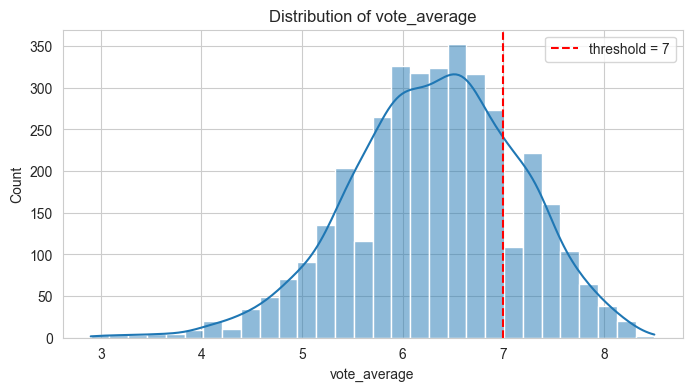

In [ ]:
sns.set_style("whitegrid")
plt.figure(figsize=(8,4))
sns.histplot(df["vote_average"], bins=30, kde=True)
plt.axvline(7,color="red", linestyle= "--", label= "threshold = 7")
plt.title("Distribution of vote_average")
plt.legend()
plt.show()

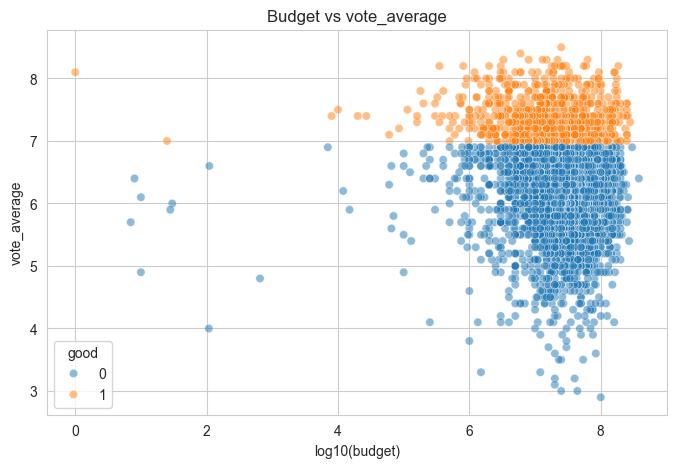

In [14]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=df, x=np.log10(df["budget"]),y="vote_average",
                hue="good", alpha=0.5)
plt.xlabel("log10(budget)")
plt.title("Budget vs vote_average")
plt.show()

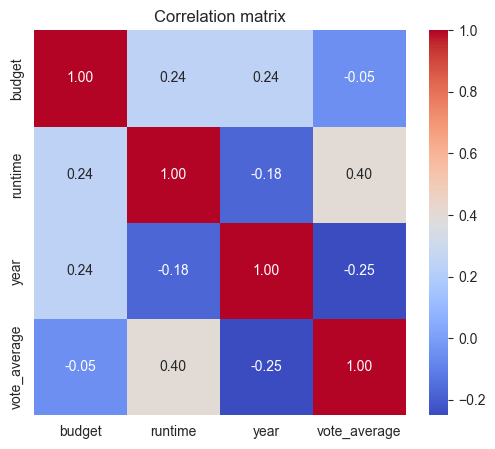

In [15]:
corr_cols = ["budget", "runtime", "year", "vote_average"]
plt.figure(figsize=(6,5))
sns.heatmap(df[corr_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation matrix")
plt.show()

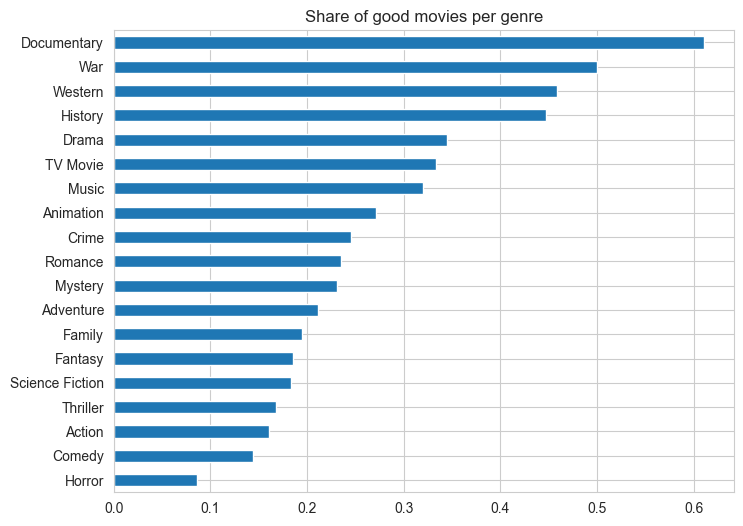

In [16]:
rate = {}
for g in genre_dummies.columns:
    mask = genre_dummies[g] == 1
    rate[g] = df.loc[mask, "good"]. mean()
rate = pd.Series(rate).sort_values()
rate.plot(kind="barh", figsize=(8,6), title="Share of good movies per genre")
plt.show()

In [17]:
models = {
    "LogisticRegression":  Pipeline([
        ("scaler", StandardScaler()) ,
        ("clf",LogisticRegression(max_iter=1000,class_weight="balanced"))
    ]),
    "RandomForest": RandomForestClassifier(
        n_estimators=300, class_weight="balanced", random_state=42
    ),
    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", KNeighborsClassifier(n_neighbors=15))
    ])
}

LogisticRegression
              precision    recall  f1-score   support

    not good       0.90      0.75      0.82       559
        good       0.47      0.73      0.57       172

    accuracy                           0.75       731
   macro avg       0.69      0.74      0.70       731
weighted avg       0.80      0.75      0.76       731



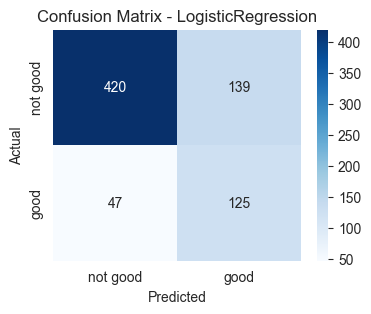

RandomForest
              precision    recall  f1-score   support

    not good       0.84      0.96      0.89       559
        good       0.73      0.39      0.51       172

    accuracy                           0.82       731
   macro avg       0.78      0.67      0.70       731
weighted avg       0.81      0.82      0.80       731



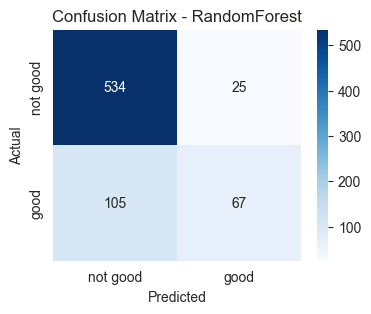

KNN
              precision    recall  f1-score   support

    not good       0.81      0.95      0.88       559
        good       0.65      0.28      0.39       172

    accuracy                           0.79       731
   macro avg       0.73      0.62      0.63       731
weighted avg       0.77      0.79      0.76       731



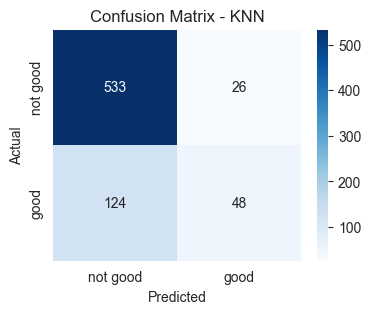

In [18]:
results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision (good)": precision_score(y_test, pred),
        "Recall (good)": recall_score(y_test, pred),
        "F1 (good)": f1_score(y_test, pred),
    })
    
    print("=" * 50)
    print(name)
    print(classification_report(y_test,pred,target_names=["not good" , "good"]))
    plt.figure(figsize=(4,3))
    sns.heatmap(confusion_matrix(y_test,pred), annot=True,fmt="d", cmap="Blues",xticklabels=["not good","good"], yticklabels=["not good", "good"])
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(f"Confusion Matrix - {name}")
    plt.show()
    

In [19]:
results_df = pd.DataFrame(results).set_index("Model").round(3)
results_df

,Accuracy,Precision (good),Recall (good),F1 (good)
Model,,,,
LogisticRegression,0.746,0.473,0.727,0.573
RandomForest,0.822,0.728,0.390,0.508
KNN,0.795,0.649,0.279,0.390


<div dir="rtl">

## مقایسه‌ی مدل‌ها

| مدل | Accuracy | Precision (good) | Recall (good) | F1 (good) |
|---|---|---|---|---|
| Logistic Regression | 0.746 | 0.473 | 0.727 | 0.573 |
| Random Forest | 0.822 | 0.728 | 0.390 | 0.508 |
| KNN | 0.795 | 0.649 | 0.279 | 0.390 |

- فقط حدود ۲۳٪ فیلم‌ها «خوب» هستن (امتیاز ۷ یا بیشتر)، پس Accuracy به‌تنهایی گمراه‌کننده‌ست: مدلی که همیشه بگه «خوب نیست» هم حدود ۷۶٪ دقت می‌گیره. برای همین به Precision و Recall و F1 کلاس «خوب» نگاه کردیم.
- **Logistic Regression** بیشترین فیلم‌های خوب رو پیدا می‌کنه (Recall برابر ۰.۷۲۷ و بهترین F1)، ولی هشدار الکی هم زیاد می‌ده (Precision برابر ۰.۴۷۳).
- **Random Forest** بالاترین Accuracy (۰.۸۲۲) و Precision (۰.۷۲۸) رو داره: وقتی می‌گه فیلمی خوبه، حدود ۷۳٪ مواقع درست می‌گه. ضعفش Recall پایینه (۰.۳۹۰)، یعنی خیلی از فیلم‌های خوب رو از دست می‌ده.
- **KNN** ضعیف‌ترینه (F1 برابر ۰.۳۹۰). این مدل گزینه‌ی `class_weight` نداره، پس بین همسایه‌ها کلاس اکثریت («خوب نیست») بیشتر رأی می‌آره.
- **مدل انتخابی: Random Forest.** برای پیشنهاد فیلم، بدترین اتفاق اینه که فیلم بد رو «خوب» معرفی کنیم، پس Precision از Recall مهم‌تره. از دست دادن بعضی فیلم‌های خوب مشکلی نداره چون فیلم‌های زیاد دیگه‌ای برای پیشنهاد هست.

</div>

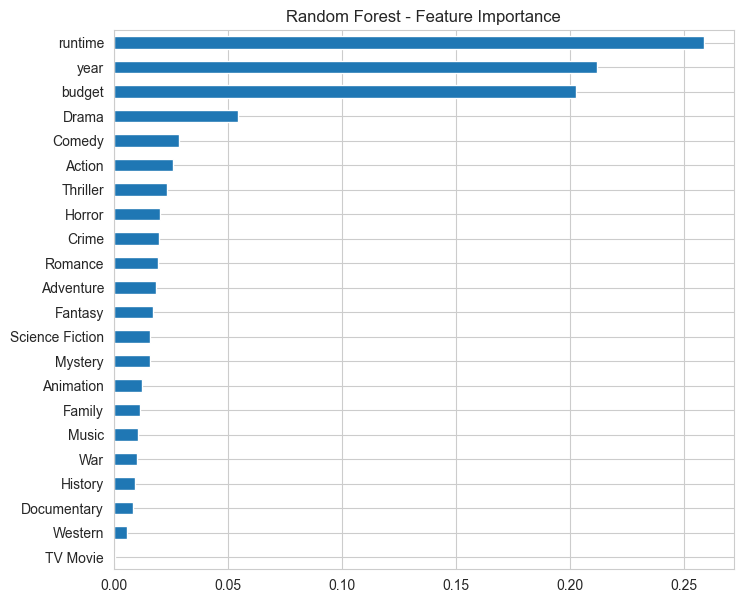

In [22]:
rf = models["RandomForest"]
importances = pd.Series(rf.feature_importances_ , index = X_train.columns).sort_values()
importances.plot(kind="barh",figsize= (8,7),title="Random Forest - Feature Importance")
plt.show()

<div dir="rtl">

## خلاصه‌ی اهمیت ویژگی‌ها

**از نگاه Random Forest، چی باعث می‌شه یه فیلم «خوب» باشه؟**

- سه ویژگی مهم‌تر از بقیه همگی عددی هستن: `runtime` (حدود ۰.۲۶)، `year` (حدود ۰.۲۱) و `budget` (حدود ۰.۲۰). این سه تا روی هم حدود دوسوم کل اهمیت رو دارن.
- بین ژانرها، `Drama` مهم‌ترینه (حدود ۰.۰۵) و بعدش `Comedy` و `Action` هستن. ژانرهایی مثل `Western` و `Documentary` و `TV Movie` تقریباً هیچ اثری روی مدل ندارن.
- نکته‌ی احتیاطی: Random Forest به ویژگی‌های پیوسته امتیاز بیشتری می‌ده، چون درخت می‌تونه روشون با آستانه‌های مختلف زیادی برش بزنه، ولی ژانر فقط دو حالت داره (۰ یا ۱). پس اهمیت کم ژانرها لزوماً یعنی ژانر بی‌اثره، فقط یعنی این روش به ویژگی‌های عددی سوگیری داره.
- بخشی از اهمیت `budget` ممکنه گمراه‌کننده باشه، چون حدود هزار فیلم بودجه‌ی ثبت‌شده نداشتن و با median پر شدن.
- محدودیت: مدل فقط مدت، سال انتشار، بودجه و ژانر رو می‌بینه و از کارگردان، بازیگر، داستان و تبلیغات خبر نداره. پس نباید از این ویژگی‌ها دقت خیلی بالا انتظار داشت.

</div>